A college wants to predict whether students will get placed.

The dataset contains

Features: Age, Gender, CGPA, Attendance, Study Hours, Family Income, Hosteller, Internet Usage, Assignments, Projects, Sports, Seminar Score, Backlogs, Lab Marks, Programming Score, Communication Score

Total Features: 16 Features

Do we need all 16 features?

Problem

More features -> More computation -> More memory -> Slower training -> Sometimes lower accuracy

This problem is called High Dimensional Data

Imagine carrying luggage.

Bag 1: Laptop

Bag 2: Books

Bag 3: Clothes

Bag 4: Shoes

Bag 5: Snacks

Instead of carrying five bags, you buy one large suitcase. Nothing important is lost. Everything is packed efficiently.

PCA does exactly this.

It compresses information

**Principal Component Analysis (PCA) is**

A dimensionality reduction technique that converts many correlated features into a smaller number of new features (called Principal Components) while retaining as much information (variance) as possible.

Why Do We Need PCA?

Suppose our dataset has

100 Features

Some are useful.

Some are duplicates.

Some are highly correlated.

Example

Attendance and Class Participation

Usually, High Attendance leads to High Participation

Both provide similar information. PCA combines them.

Principal Components are new artificial features. They are combinations of original features.
Example- PC1 = 0.6(CGPA) + 0.3(Attendance) + 0.1(Study Hours)

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/student_dataset.csv")

In [ ]:
features = [
    "Age",
    "CGPA",
    "Attendance",
    "Study_Hours",
    "Backlogs"
]

X = df[features].dropna()

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [ ]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1","PC2"]
)

print(pca_df.head())
# They are new coordinates that summarize the information
# from the original six features. Each row still represents one student, but in a reduced feature space.

        PC1       PC2
0 -0.757453 -0.244002
1  1.378190 -0.434984
2  0.249368  0.159211
3 -1.076769 -0.139156
4 -0.378218 -0.233387


In [ ]:
print(pca.explained_variance_ratio_)

[0.22626971 0.21309406]


In [ ]:
import numpy as np

cumulative = np.cumsum(
    pca.explained_variance_ratio_
)

print(cumulative)

[0.22626971 0.43936377]


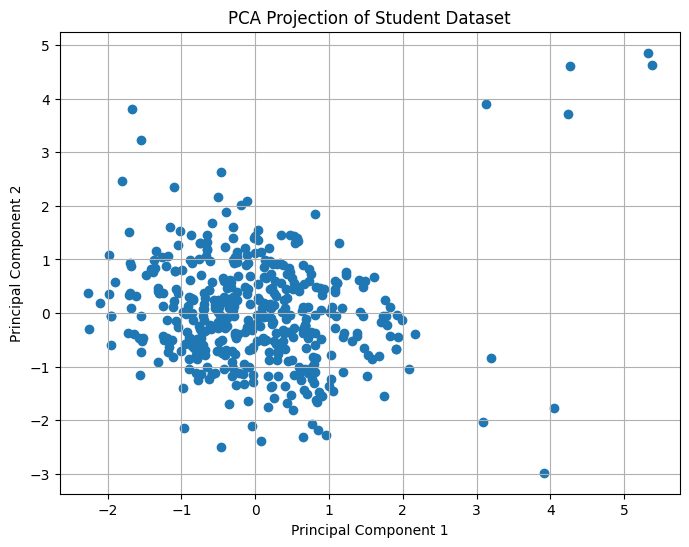

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"]
)

plt.title("PCA Projection of Student Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.grid(True)

plt.show()

# Every point represents one student.
# Students close together have similar characteristics.
# Students far apart are different.

Real-World Applications

Face Recognition

A high-resolution image may have thousands of pixel values. PCA reduces these to a much smaller set of components while preserving important facial characteristics.

Healthcare

Hospitals collect hundreds of medical measurements. PCA helps reduce these variables before disease prediction models are trained.

Finance

Banks analyze dozens of financial indicators. PCA summarizes them into a few components for credit risk analysis.

Recommendation Systems

Streaming platforms and e-commerce websites use PCA to compress user preferences and product characteristics, making recommendations faster.